# 03 · EDA Longitudinal — OASIS-2

## Objetivo

El análisis baseline estudió a cada participante en su primera visita. En este notebook se incorpora la dimensión temporal para responder una pregunta diferente:

**¿Cómo evolucionan a lo largo del seguimiento los pacientes Nondemented, Demented y Converted, y existen diferencias en sus trayectorias de MMSE y nWBV?**

OASIS-2 contiene varias visitas por sujeto, por lo que el tiempo entre exploraciones y el número de visitas no es idéntico para todos los participantes.

> **Privacidad y uso de datos:** el dataset original OASIS-2 no se distribuye con este repositorio. Se conservan código, estadísticas agregadas y visualizaciones derivadas, evitando publicar registros individuales e identificadores de participantes.


## Variables longitudinales clave

Para interpretar este notebook conviene recordar cuatro conceptos:

| Variable | Significado | ¿Por qué importa aquí? |
|---|---|---|
| `Visit` | Número de visita del participante | Permite ordenar las evaluaciones sucesivas. |
| `MR Delay` | Días transcurridos desde la visita inicial | Representa el tiempo real de seguimiento y permite comparar cambios ocurridos en periodos distintos. |
| `MMSE` | Mini-Mental State Examination (0–30) | Evalúa globalmente el rendimiento cognitivo. Una disminución a lo largo del tiempo puede reflejar deterioro cognitivo, aunque MMSE por sí solo no diagnostica demencia. |
| `nWBV` | Normalized Whole Brain Volume | Estimación del volumen cerebral total normalizado por el tamaño intracraneal. Su evolución permite estudiar cambios estructurales cerebrales durante el seguimiento. |

### ¿Qué significa “cambio anual”?

Los participantes no fueron evaluados durante exactamente el mismo número de años. Por ello, además del cambio entre primera y última visita, se calcula una **tasa anualizada**:

**Cambio anual = (valor final − valor inicial) / años de seguimiento**

Un valor negativo de `Cambio_anual_MMSE` indica una disminución de la puntuación cognitiva. Un valor negativo de `Cambio_anual_nWBV` indica una reducción del volumen cerebral normalizado.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats import f_oneway
from scipy.stats import levene
from scipy.stats import shapiro
from scipy.stats import kruskal
from scipy.stats import mannwhitneyu
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [2]:
df_oasis2 = pd.read_excel("../data/oasis_2.xlsx")

## 1. De visitas a pacientes

Antes de analizar trayectorias es fundamental distinguir entre **filas del dataset** y **personas**. Un mismo `Subject ID` aparece varias veces porque OASIS-2 registra distintas visitas.

Para los cálculos longitudinales se ordenarán las observaciones de cada sujeto cronológicamente y se resumirá su evolución a nivel de paciente.


In [5]:
df_oasis2.groupby('Subject ID')['Age'].agg(['first', 'last']).shape

(150, 2)

In [7]:
seguimiento = df_oasis2.groupby('Subject ID').agg(
        Num_visitas=('Visit', 'count'),
    MR_Delay_inicial=('MR Delay', 'min'),
    MR_Delay_final=('MR Delay', 'max')
)

In [9]:
seguimiento['Num_visitas'].value_counts()

Num_visitas
2    94
3    43
4     9
5     4
Name: count, dtype: int64

Los 150 participantes tienen entre **2 y 5 visitas**. Esta heterogeneidad es relevante: no todos aportan el mismo número de observaciones ni tienen exactamente la misma duración de seguimiento.


In [11]:
tabla_Group = df_oasis2[['Subject ID', 'Group']].drop_duplicates()

In [13]:
seguimiento = seguimiento.reset_index()

In [15]:
tabla_seguimiento = pd.merge(
    seguimiento,
    tabla_Group,
    on='Subject ID',
    how='left'
)

## 2. Duración del seguimiento

Antes de comparar cambios longitudinales se analiza cuánto tiempo fue seguido cada grupo. `MR_Delay_final` representa el número de días transcurridos entre la visita inicial y la última evaluación disponible.


In [17]:
tabla_seguimiento.groupby('Group')['MR_Delay_final'].agg(['mean', 'median', 'std'])

,mean,median,std
Group,,,
Converted,1409.714286,1492.5,579.972072
Demented,833.859375,660.0,435.627403
Nondemented,1210.819444,1119.5,536.887832


<Axes: xlabel='Group', ylabel='MR_Delay_final'>

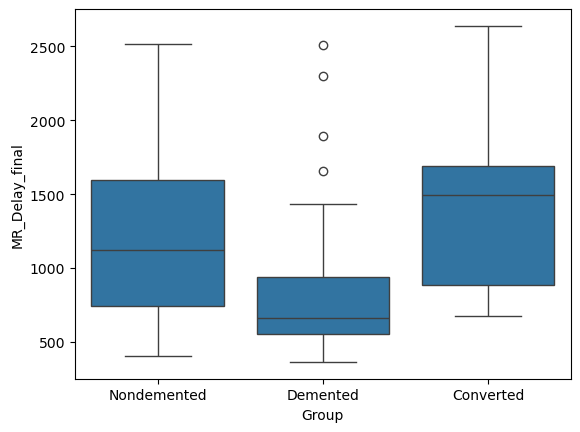

In [19]:
sns.boxplot(
    data=tabla_seguimiento,
    x='Group',
    y='MR_Delay_final'
)

Descriptivamente, Converted presenta el mayor tiempo de seguimiento, seguido de Nondemented, mientras que Demented presenta el menor.

La prueba de Kruskal-Wallis muestra diferencias globales entre grupos. Las comparaciones post-hoc permiten identificar qué grupos explican esas diferencias.


In [21]:
MR_Delay_final_converted= tabla_seguimiento[
    tabla_seguimiento['Group']=='Converted']['MR_Delay_final']

In [23]:
MR_Delay_final_demented= tabla_seguimiento[
    tabla_seguimiento['Group']=='Demented']['MR_Delay_final']

In [25]:
MR_Delay_final_Nondemented= tabla_seguimiento[
    tabla_seguimiento['Group']=='Nondemented']['MR_Delay_final']

In [27]:
kruskal(
    MR_Delay_final_Nondemented,
    MR_Delay_final_demented,
    MR_Delay_final_converted
)

KruskalResult(statistic=29.048947133754375, pvalue=4.921542925480685e-07)

In [29]:
mannwhitneyu(
    MR_Delay_final_converted,
    MR_Delay_final_Nondemented
)

MannwhitneyuResult(statistic=609.0, pvalue=0.22154594567717956)

In [31]:
mannwhitneyu(
    MR_Delay_final_converted,
     MR_Delay_final_demented
)

MannwhitneyuResult(statistic=739.0, pvalue=0.00015528411145255189)

In [33]:
mannwhitneyu(
    MR_Delay_final_Nondemented,
     MR_Delay_final_demented
)

MannwhitneyuResult(statistic=3399.0, pvalue=1.8248490011274372e-06)

**Interpretación.** El tiempo de seguimiento difirió significativamente entre los tres grupos (Kruskal-Wallis, p < 0,001). Tras las comparaciones post-hoc, Demented presentó un seguimiento significativamente menor que Converted y Nondemented. En cambio, no se encontró evidencia de una diferencia entre Converted y Nondemented (p = 0,222).

Esta diferencia entre grupos debe tenerse presente al interpretar la evolución longitudinal. Por ello, para MMSE y nWBV se utilizarán tasas de cambio anualizadas.


## 3. ¿Cómo evolucionan los pacientes Converted?

`Converted` identifica a sujetos cuya trayectoria clínica cambia durante el seguimiento. Resulta especialmente interesante observar cómo evolucionan sus medidas cognitivas y cerebrales.

Las siguientes visualizaciones muestran las trayectorias de **MMSE**, **CDR** y **nWBV** en función de los días transcurridos desde la primera visita.

### CDR como referencia clínica

`CDR` (Clinical Dementia Rating) es una escala clínica de gravedad: 0 indica ausencia de demencia, 0.5 deterioro muy leve/cuestionable y valores superiores representan grados crecientes de demencia. Aquí se utiliza para **describir la trayectoria clínica**, no como una prueba aislada de Alzheimer.


In [35]:
df_converted = df_oasis2[df_oasis2['Group']== 'Converted']

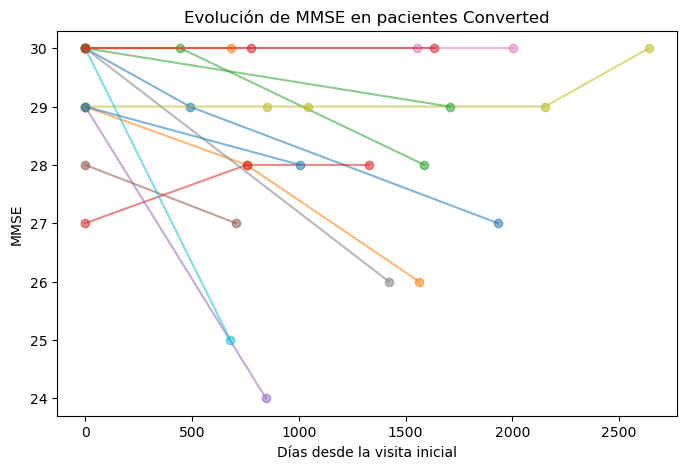

In [37]:
plt.figure(figsize=(8, 5))
for _, paciente in df_converted.groupby('Subject ID'):
    plt.plot(paciente['MR Delay'], paciente['MMSE'], marker='o', alpha=0.55)

plt.xlabel('Días desde la visita inicial')
plt.ylabel('MMSE')
plt.title('Evolución de MMSE en pacientes Converted')
plt.show()


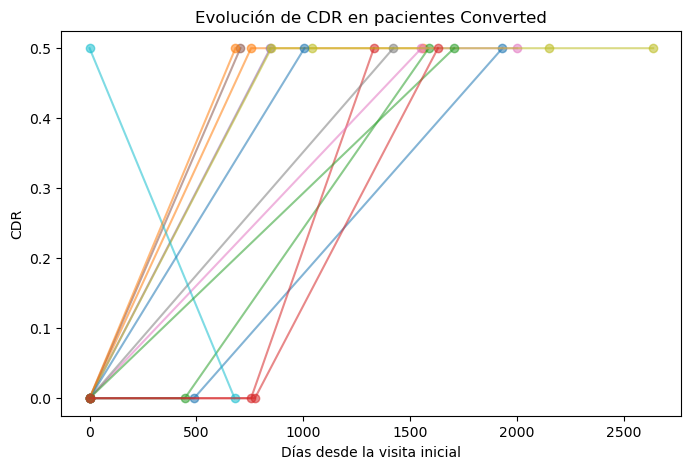

In [39]:
plt.figure(figsize=(8, 5))
for _, paciente in df_converted.groupby('Subject ID'):
    plt.plot(paciente['MR Delay'], paciente['CDR'], marker='o', alpha=0.55)

plt.xlabel('Días desde la visita inicial')
plt.ylabel('CDR')
plt.title('Evolución de CDR en pacientes Converted')
plt.show()


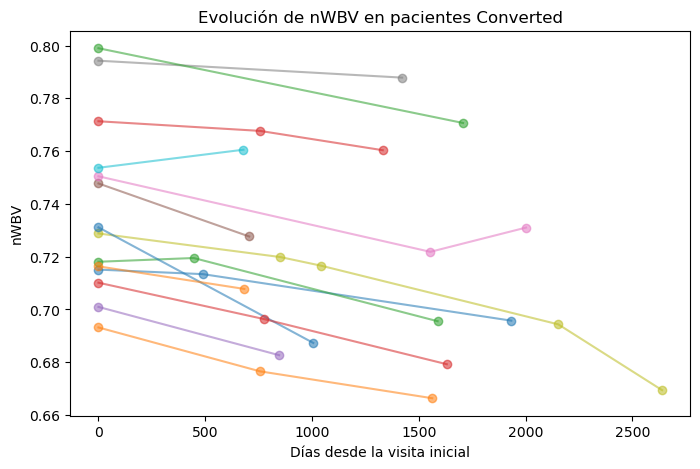

In [41]:
plt.figure(figsize=(8, 5))
for _, paciente in df_converted.groupby('Subject ID'):
    plt.plot(paciente['MR Delay'], paciente['nWBV'], marker='o', alpha=0.55)

plt.xlabel('Días desde la visita inicial')
plt.ylabel('nWBV')
plt.title('Evolución de nWBV en pacientes Converted')
plt.show()


Las trayectorias individuales muestran heterogeneidad entre los sujetos Converted. En varios pacientes se observa disminución de MMSE y aumento de CDR a lo largo del seguimiento, mientras que nWBV presenta una tendencia general descendente en muchos sujetos.

Estas trayectorias no deben interpretarse como un patrón determinista: existen fluctuaciones individuales y el número y duración de las visitas varían entre participantes.


## 4. Cambio anual de nWBV

### ¿Disminuye el volumen cerebral normalizado a distinta velocidad según el grupo?

Para cada sujeto se toman la primera y la última visita ordenadas por `MR Delay`. A continuación se calcula el cambio de nWBV y se divide por los años de seguimiento.

Este procedimiento resume la trayectoria en una única tasa anual y facilita la comparación entre pacientes con seguimientos de diferente duración.


In [43]:
df_ordenado= df_oasis2.sort_values(
    by= ['Subject ID', 'MR Delay']
)

In [45]:
evolucion_nWBV = df_ordenado.groupby('Subject ID').agg(
    nWBV_inicial=('nWBV', 'first'),
    nWBV_final=('nWBV', 'last'),
    MR_Delay_inicial=('MR Delay','min'),
    MR_Delay_final=('MR Delay', 'max')
)

In [47]:
evolucion_nWBV['Cambio_nWBV'] = ( 
    evolucion_nWBV['nWBV_final'] - evolucion_nWBV['nWBV_inicial'] 
                                )

In [49]:
evolucion_nWBV['Tiempo_años'] = ( 
    (evolucion_nWBV['MR_Delay_final'] - evolucion_nWBV['MR_Delay_inicial'] )/365.25
                                )

In [51]:
evolucion_nWBV['Cambio_anual_nWBV'] = ( 
    (evolucion_nWBV['Cambio_nWBV'] / evolucion_nWBV['Tiempo_años'] )
                                )

In [53]:
evolucion_nWBV = evolucion_nWBV.reset_index()

In [55]:
 evolucion_nWBV_grupos = pd.merge(
    evolucion_nWBV,
    tabla_Group,
    on='Subject ID',
    how='left'
)

In [57]:
evolucion_nWBV_grupos.groupby('Group')['Cambio_anual_nWBV'].agg([
    'mean',
    'median',
    'std'
])

,mean,median,std
Group,,,
Converted,-0.005685,-0.005622,0.004484
Demented,-0.006406,-0.005314,0.007305
Nondemented,-0.003582,-0.003878,0.004124


Descriptivamente, Nondemented presenta una pérdida anual media de nWBV menor que Converted y Demented. Sin embargo, es necesario comprobar si estas diferencias son estadísticamente consistentes.


In [60]:
variable_converted = evolucion_nWBV_grupos[
    evolucion_nWBV_grupos['Group'] == 'Converted'
]['Cambio_anual_nWBV']

In [62]:
variable_Demented = evolucion_nWBV_grupos[
    evolucion_nWBV_grupos['Group'] == 'Demented'
]['Cambio_anual_nWBV']

In [64]:
variable_Nondemented = evolucion_nWBV_grupos[
    evolucion_nWBV_grupos['Group'] == 'Nondemented'
]['Cambio_anual_nWBV']

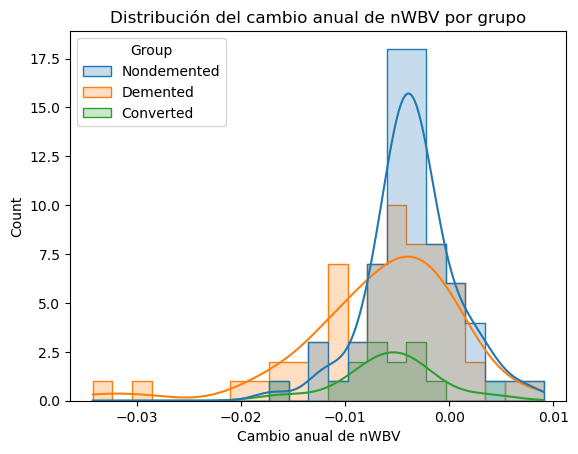

In [66]:
sns.histplot(
    data=evolucion_nWBV_grupos,
    x='Cambio_anual_nWBV',
    hue='Group',
    kde=True,
    element='step'
)
plt.xlabel('Cambio anual de nWBV')
plt.title('Distribución del cambio anual de nWBV por grupo')
plt.show()


In [68]:
shapiro(variable_converted)

ShapiroResult(statistic=0.9554326458129623, pvalue=0.6477310033229201)

In [70]:
shapiro(variable_Demented)

ShapiroResult(statistic=0.9144532080559715, pvalue=0.000293864539897789)

In [72]:
shapiro(variable_Nondemented)

ShapiroResult(statistic=0.9652923218778973, pvalue=0.04426155442731783)

In [74]:
levene(
    variable_converted,
    variable_Demented,
    variable_Nondemented
)

LeveneResult(statistic=5.513635763548893, pvalue=0.004909293965443297)

In [76]:
kruskal(
    variable_converted,
    variable_Demented,
    variable_Nondemented
)

KruskalResult(statistic=6.232542836119023, pvalue=0.04432211936586505)

In [78]:
mannwhitneyu(
   variable_converted,
    variable_Demented
)

MannwhitneyuResult(statistic=439.0, pvalue=0.9118755934849239)

In [80]:
mannwhitneyu(
   variable_Demented,
    variable_Nondemented
)

MannwhitneyuResult(statistic=1803.0, pvalue=0.029100842016132517)

In [82]:
mannwhitneyu(variable_converted, variable_Nondemented)


MannwhitneyuResult(statistic=347.0, pvalue=0.06714666076554142)

**Interpretación.** El cambio anual de nWBV mostró diferencias globales entre los grupos (Kruskal-Wallis: H = 6,23; p = 0,044). Sin embargo, al aplicar la corrección de Bonferroni para las tres comparaciones post-hoc (α = 0,0167), ninguna comparación por pares alcanzó significación estadística.

Existe, por tanto, una **tendencia descriptiva** hacia una mayor pérdida anual de nWBV en Converted y Demented respecto a Nondemented, pero la evidencia estadística por pares es débil en esta muestra.


## 5. Cambio anual de MMSE

### ¿Difiere la velocidad de cambio cognitivo entre los grupos?

Se aplica el mismo procedimiento a MMSE: se compara la puntuación de la primera y la última visita y se divide el cambio por los años de seguimiento.

Una tasa cercana a 0 indica estabilidad aproximada; una tasa negativa indica una disminución anual de la puntuación MMSE.


In [84]:
evolucion_nWBV_MMSE = df_ordenado.groupby('Subject ID').agg(
    nWBV_inicial=('nWBV', 'first'),
    nWBV_final=('nWBV', 'last'),
    MR_Delay_inicial=('MR Delay','min'),
    MR_Delay_final=('MR Delay', 'max'),
    MMSE_inicial=('MMSE', 'first'),
    MMSE_final=('MMSE', 'last')
)

In [86]:
evolucion_nWBV_MMSE['Evolucion_MMSE'] = ( 
    evolucion_nWBV_MMSE['MMSE_final'] - evolucion_nWBV_MMSE['MMSE_inicial'] 
                                )

In [88]:
evolucion_nWBV_MMSE['Tiempo_años_2'] = ( 
    (evolucion_nWBV_MMSE['MR_Delay_final'] - evolucion_nWBV_MMSE['MR_Delay_inicial'] )/365.25
                                )

In [90]:
evolucion_nWBV_MMSE['Cambio_anual_MMSE'] = ( 
    (evolucion_nWBV_MMSE['Evolucion_MMSE'] / evolucion_nWBV_MMSE['Tiempo_años_2'] )
                                )

In [92]:
evolucion_nWBV_MMSE = evolucion_nWBV_MMSE.reset_index()


In [94]:
 evolucion_MMSE = pd.merge(
    evolucion_nWBV_MMSE,
    tabla_Group,
    on='Subject ID',
    how='left'
)

In [96]:
 evolucion_MMSE.groupby('Group')['Cambio_anual_MMSE'].agg([
    'mean',
    'median',
    'std'
])

,mean,median,std
Group,,,
Converted,-0.591803,-0.411542,0.859808
Demented,-0.739615,-0.372858,1.700784
Nondemented,-0.034704,0.000000,0.621811


Descriptivamente, Nondemented permanece aproximadamente estable en MMSE, mientras que Converted y Demented presentan una disminución media más marcada.


In [98]:
variable_converted_MMSE = evolucion_MMSE[
    evolucion_MMSE['Group'] == 'Converted'
]['Cambio_anual_MMSE']

In [100]:
variable_Demented_MMSE = evolucion_MMSE[
    evolucion_MMSE['Group'] == 'Demented'
]['Cambio_anual_MMSE']

In [102]:
variable_Nondemented_MMSE = evolucion_MMSE[
    evolucion_MMSE['Group'] == 'Nondemented'
]['Cambio_anual_MMSE']

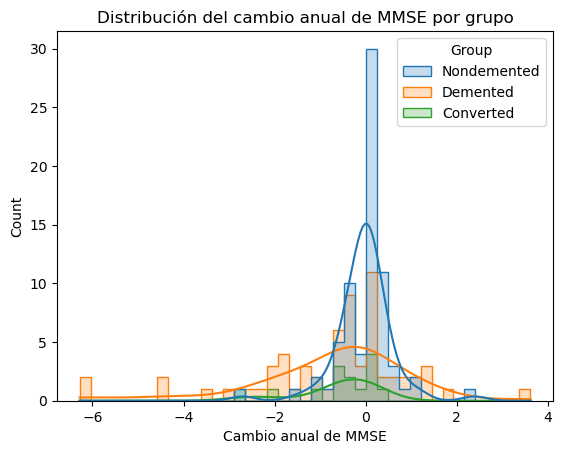

In [104]:
sns.histplot(
    data=evolucion_MMSE,
    x='Cambio_anual_MMSE',
    hue='Group',
    kde=True,
    element='step'
)
plt.xlabel('Cambio anual de MMSE')
plt.title('Distribución del cambio anual de MMSE por grupo')
plt.show()


In [106]:
shapiro(variable_converted_MMSE)

ShapiroResult(statistic=0.8113491350783916, pvalue=0.00691875492233973)

In [108]:
shapiro(variable_Demented_MMSE)

ShapiroResult(statistic=0.899451398477237, pvalue=7.630337761935548e-05)

In [110]:
shapiro(variable_Nondemented_MMSE)

ShapiroResult(statistic=0.8591413959578966, pvalue=9.955691600723717e-07)

In [112]:
levene(
    variable_converted_MMSE,
    variable_Demented_MMSE,
    variable_Nondemented_MMSE
)

LeveneResult(statistic=11.499746593666272, pvalue=2.2904644011938805e-05)

In [114]:
kruskal (
    variable_converted_MMSE,
    variable_Demented_MMSE,
    variable_Nondemented_MMSE
)

KruskalResult(statistic=13.433242935009387, pvalue=0.0012106214362863996)

In [116]:
mannwhitneyu(
    variable_Demented_MMSE,
    variable_Nondemented_MMSE
)

MannwhitneyuResult(statistic=1555.5, pvalue=0.0009953428816069413)

In [118]:
mannwhitneyu(
    variable_Demented_MMSE,
    variable_converted_MMSE
)

MannwhitneyuResult(statistic=446.5, pvalue=0.9895814670190303)

In [120]:
mannwhitneyu(
    variable_Nondemented_MMSE,
    variable_converted_MMSE
)

MannwhitneyuResult(statistic=718.5, pvalue=0.010846470878464446)

Las distribuciones de cambio anual de MMSE se apartan de la normalidad y presentan varianzas diferentes, por lo que se utiliza Kruskal-Wallis seguido de comparaciones Mann–Whitney.

Con tres comparaciones post-hoc se aplica una corrección de Bonferroni:

**α = 0,05 / 3 = 0,0167**


**Interpretación.** La tasa anual de cambio de MMSE mostró diferencias globales entre los grupos (Kruskal-Wallis: H = 13,43; p = 0,0012).

Tras la corrección de Bonferroni:

- Demented vs Nondemented: diferencia significativa (p ≈ 0,0010).
- Nondemented vs Converted: diferencia significativa (p ≈ 0,0108).
- Demented vs Converted: no se encontró evidencia de diferencia (p ≈ 0,990).

En esta cohorte, **Converted y Demented muestran un mayor descenso anual de MMSE que Nondemented**. Esta diferencia longitudinal es más clara que la observada para nWBV.


# Conclusiones del EDA longitudinal

El análisis longitudinal aporta información que no era visible con la misma claridad en la visita inicial:

- Los participantes Demented tuvieron, en promedio, un seguimiento más corto que Nondemented y Converted.
- nWBV disminuyó durante el seguimiento en los tres grupos. Converted mostró descriptivamente una pérdida mayor que Nondemented, aunque las comparaciones por pares no fueron significativas tras corregir por comparaciones múltiples.
- MMSE mostró una diferencia longitudinal más clara: Converted y Demented presentaron un descenso anual significativamente mayor que Nondemented.
- Las trayectorias individuales son heterogéneas y no todos los pacientes evolucionan de la misma manera.

Estos resultados sugieren que **la evolución temporal puede contener información que una única visita no captura**. Sin embargo, las tasas calculadas utilizan información posterior al baseline y, por tanto, no deben interpretarse como variables disponibles para una predicción precoz.

El siguiente análisis utilizará estas trayectorias con un objetivo diferente: estudiar retrospectivamente hasta qué punto las características longitudinales permiten discriminar entre sujetos Converted y Nondemented.
